In [1]:
import sympy as sp
import numpy as np
from fit_file import X_sq
import matplotlib.pyplot as plt

#PROEF 1

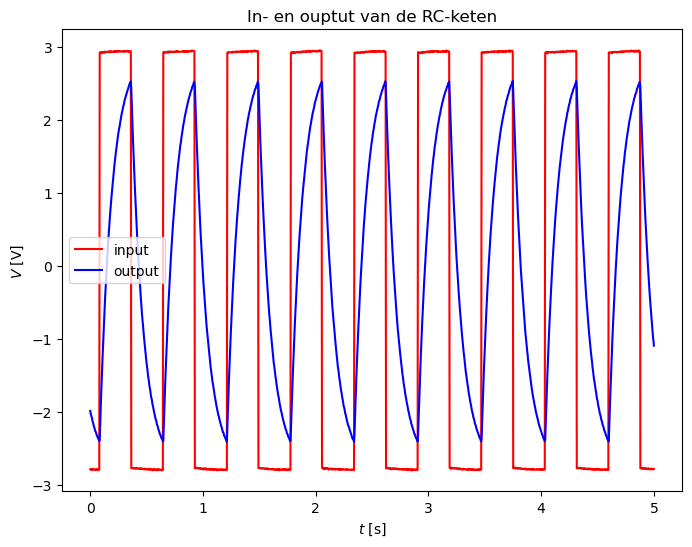

In [2]:
###PROEF 1 - RC-KETEN
#data inladen
gemeten_data = np.loadtxt(fname = "data/Proef1(RC).txt", skiprows = 7, converters=lambda s: float(s.replace(b',', b'.'))).T
t = gemeten_data[0] #s
input = gemeten_data[1] #V
output = gemeten_data[2] #V

fig, ax = plt.subplots(figsize = (8, 6))
ax.plot(t, input, label = 'input', color = 'red')
ax.plot(t, output, label = 'output', color = 'blue')
ax.set_xlabel(r'$t$ [s]')
ax.set_ylabel(r'$V$ [V]')
ax.set_title(r'In- en ouptut van de RC-keten')
ax.legend()

In [3]:
#verwerken

opladen_t = t[21:91]
opladen_V = output[21:91]
ontladen_t = t[91:162]
ontladen_V = input[91:162]

halve_periode = 0.28 #s, 70 * 0.004
halve_frequentie = 1 / halve_periode


###fitten opladen
#normaliseren (min max scaling)
V_max = np.max(output)
V_min = np.min(output)
V_norm = (output - V_min) / (V_max - V_min)

opladen_V_norm = V_norm[21:91].astype(float)
ontladen_V_norm = V_norm[91:162].astype(float)
fout_absoluut = 4.9e-3

def normaliseer_fout(V_echt, Vmax, Vmin, dVmax, dVmin, dV):
    V, V_max, V_min = sp.symbols("V V_max V_min")
    V_norm = (V - V_min) / (V_max - V_min)
    s_func = sp.sqrt((sp.diff(V_norm, V))**2 * dV**2 + (sp.diff(V_norm, V_max))**2 * dVmax**2 + (sp.diff(V_norm, V_min))**2 * dVmin**2)
    s = s_func.subs([(V, V_echt), (V_max, Vmax), (V_min, Vmin)])
    return s

dV = [] #genormaliseerde fout
for i in V_norm:
    dV.append(normaliseer_fout(i, V_max, V_min, fout_absoluut, fout_absoluut, fout_absoluut))

#fitten - voorbereiding
def model_opladen(params, t):
    tau = params
    return 1 - np.exp(-t/tau)

def model_ontladen(params, t):
    tau = params
    return - np.exp(-t/tau) + np.exp(-(t-halve_periode)/tau)

dt = np.array(np.full(200, 0.004, dtype = float)).astype(float)
dV = np.array(dV).astype(float)

param_names = [r'$\tau$']
print(dV)


[0.00121421 0.0012142  0.00121419 ... 0.00121594 0.0012158  0.00121559]


In [4]:
#fitten - opladen
X_sq(data = ((opladen_t - 0.084, dt[21:91]), (opladen_V_norm, dV[21:91])), param_names=param_names, initial_guess = [0.01], model = model_opladen, PLOT = False)
#fitten - ontladen
X_sq(data = ((ontladen_t - 0.084, dt[91:162]), (ontladen_V_norm, dV[91:162])), param_names=param_names, initial_guess = [0.01], model = model_ontladen, PLOT = False)


---------START--------------------------------------------------------------------------------------------------
For parameter $\tau$   :     Minimum at       0.08840175     ;     68% CI = [      0.08835575,       0.08844778]
----------------------------------------------------------------------------------------------------------------
Minimal χ² value       :     χ²_min       20923.62453355
Reduced χ² value       :     χ²_red         303.24093527
P-value                :     p-value          0.00000000
----------END---------------------------------------------------------------------------------------------------


---------START--------------------------------------------------------------------------------------------------
For parameter $\tau$   :     Minimum at       0.09132980     ;     68% CI = [      0.09127488,       0.09138478]
----------------------------------------------------------------------------------------------------------------
Minimal χ² value       :     χ²_min

In [5]:
#fouten
tau_op = 0.08840175
tau_ont = 0.09132980
sigma_op = tau_op - 0.08835575
sigma_ont = tau_ont - 0.09127488
print(tau_op, sigma_op, tau_ont, sigma_ont)

0.08840175 4.600000000000437e-05 0.0913298 5.491999999999997e-05


In [6]:
#nominale waarden
R = 10e3
C = 10e-6
dR = 0.01*R
dC = 0.01*C
tau_nom = R*C
def fout_nom(R, C, dr, dc):
    r, c = sp.symbols('r c')
    tau = r*c
    s_func = sp.sqrt(sp.diff(tau, r)**2 * dr**2 + sp.diff(tau, c)**2 * dc**2)
    s = s_func.subs([(r, R), (c, C)])
    return s

print(tau_nom, fout_nom(R, C, dR, dC))

0.1 0.00141421356237310


In [7]:
#normaliseerde curves
print(1 - np.exp(-1), np.exp(-1))
print(np.where(opladen_V_norm > 1 - np.exp(-1))) #→24*0.004 = 0.096, dit is tau
print(np.where(ontladen_V_norm < np.exp(-1))) #→24*0.004 = 0.096, dit is tau (opnieuw dus)

0.6321205588285577 0.36787944117144233
(array([24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40,
       41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57,
       58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69], dtype=int64),)
(array([24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40,
       41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57,
       58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70], dtype=int64),)


#PROEF 2

In [8]:
#inladen alle (output)data, tijd blijft lijst t
getallen = [0.2, 0.3, 0.5, 0.7, 1.0, 1.5, 1.7, 1.9, 2.0, 2.2, 2.5, 3.0, 3.5, 4.0, 5.0, 10.0]
alle_data = [] #wordt matrix: [0] is eerste meting enzovoort
for i in getallen:
    filename = f"data/Proef2 - {i}.txt"
    lijst = np.loadtxt(fname = filename, skiprows = 7, converters=lambda s: float(s.replace(b',', b'.'))).T[2]
    alle_data.append(lijst)

In [9]:
#fitten aan sinus - test
test_data = alle_data[0]

def model_sinus(params, t):
    A, omega, phi = params
    return A * np.sin(omega * t + phi) #hoekfrequentie

dt = np.array(np.full(1251, 0.004, dtype = float)).astype(float)
dV = np.array(np.full(1251, 4.9e-3, dtype = float)).astype(float)

param_names = ["A", "hoekfrequentie", "fase"]
X_sq(data = ((t, dt), (test_data,  dV)), param_names = param_names, initial_guess = (np.max(test_data), 2*np.pi * 0.2, 1), model = model_sinus, PLOT = False)
print(getallen[:11])


---------START--------------------------------------------------------------------------------------------------
For parameter A        :     Minimum at      -0.43508264     ;     68% CI = [     -0.43543422,      -0.43473104]
For parameter hoekfrequentie :     Minimum at       1.42870933     ;     68% CI = [      1.42840164,       1.42901713]
For parameter fase     :     Minimum at       0.84654395     ;     68% CI = [      0.84566076,       0.84742720]
----------------------------------------------------------------------------------------------------------------
Minimal χ² value       :     χ²_min       11088.69680845
Reduced χ² value       :     χ²_red           8.88517372
P-value                :     p-value          0.00000000
----------END---------------------------------------------------------------------------------------------------

[0.2, 0.3, 0.5, 0.7, 1.0, 1.5, 1.7, 1.9, 2.0, 2.2, 2.5]


In [10]:
#fitten alle data
for i in range(len(getallen[:11])):
    lijst = alle_data[i]
    X_sq(data = ((t, dt), (lijst, dV)), param_names = param_names, initial_guess = (np.max(test_data), 2*np.pi * getallen[i], 1), model = model_sinus, PLOT = False)


---------START--------------------------------------------------------------------------------------------------
For parameter A        :     Minimum at      -0.43508264     ;     68% CI = [     -0.43543422,      -0.43473104]
For parameter hoekfrequentie :     Minimum at       1.42870933     ;     68% CI = [      1.42840164,       1.42901713]
For parameter fase     :     Minimum at       0.84654395     ;     68% CI = [      0.84566076,       0.84742720]
----------------------------------------------------------------------------------------------------------------
Minimal χ² value       :     χ²_min       11088.69680845
Reduced χ² value       :     χ²_red           8.88517372
P-value                :     p-value          0.00000000
----------END---------------------------------------------------------------------------------------------------


---------START--------------------------------------------------------------------------------------------------
For parameter A        :     

In [11]:
#problemen oplossen door data te verwijderen
probleem_getallen = [3.0, 3.5, 4.0, 5.0, 10.0]
probleem_data = []
for i in probleem_getallen:
    filename = f"data/Proef2 - {i}.txt"
    lijst = np.loadtxt(fname = filename, skiprows = 7, converters=lambda s: float(s.replace(b',', b'.'))).T[2]
    probleem_data.append(lijst)


In [12]:
#probleem oplossen door naar 1 sec te kijken ipv 5
t_opl = t[:251]
opl = []
for i in probleem_data:
    i = i[:251]
    opl.append(i)

for i in range(len(probleem_getallen)):
    lijst = opl[i]
    X_sq(data = ((t_opl, dt[:251]), (lijst, dV[:251])), param_names = param_names, initial_guess = (np.max(lijst), 2*np.pi * probleem_getallen[i], 1), model = model_sinus, PLOT = False)




---------START--------------------------------------------------------------------------------------------------
For parameter A        :     Minimum at       2.78864588     ;     68% CI = [      2.78782155,       2.78947023]
For parameter hoekfrequentie :     Minimum at      20.02985134     ;     68% CI = [     20.02935325,      20.03034947]
For parameter fase     :     Minimum at       0.05679147     ;     68% CI = [      0.05649968,       0.05708328]
----------------------------------------------------------------------------------------------------------------
Minimal χ² value       :     χ²_min       11095.44219450
Reduced χ² value       :     χ²_red          44.73968627
P-value                :     p-value          0.00000000
----------END---------------------------------------------------------------------------------------------------


---------START--------------------------------------------------------------------------------------------------
For parameter A        :     

In [13]:
#DATA (MANUAL LABOR)
alle_amp = np.array([0.43508264, 0.64173840, 1.05019821, 1.37130573, 1.77920804, 2.17041987, 2.33571152, 2.43117229, 2.47956706, 2.59315546, 2.65559995, 2.78864588, 2.85609694, 2.92049948, 2.97532278, 3.05519247])
damp_voor = np.array([0.43473104, 0.64136933, 1.04983402, 1.37094591, 1.77883760, 2.17005239, 2.33534763, 2.43080469, 2.47920037, 2.59278674, 2.65523492, 2.78782155, 2.85526364, 2.91968799, 2.97451028, 3.05437364])
damp = alle_amp - damp_voor

alle_hoekfreq = np.array([1.42870933, 2.03271417, 3.43922938, 4.69250179, 6.67818060, 9.38368395, 10.96626836, 12.11078168, 12.77051506, 14.66479259, 16.01473897, 20.02985134, 23.25901876, 27.43355957, 33.84916314, 65.75034374])
dhoek_voor = np.array([1.42840164, 2.03252700, 3.43910713, 4.69240631, 6.67810975, 9.38362538, 10.96621328, 12.11072921, 12.77046352, 14.66474409, 16.01469078, 20.02935325, 23.25853330, 27.43307459, 33.84868161, 65.74987527])
dhoek = alle_hoekfreq - dhoek_voor

alle_fase = np.array([0.84654395, 0.32529691, 0.16925529, 1.02480006, -0.59941008, 1.76200452, 1.08969750, -1.05610237, -1.32372556, -0.22917495, 0.47818740, 0.05679147, -0.94485719, -2.36989099, -2.77833179, 2.16845118])
dfase_voor = np.array([0.84566076, 0.32472870, 0.16890340, 1.02452712, -0.59961429, 1.76183581, 1.08953916, -1.05625295, -1.32387356, -0.22931570, 0.47804858, 0.05649968, -0.94513916, -2.37017404, -2.77860927, 2.16818307])
dfase = np.abs(alle_fase - dfase_voor)



---------START--------------------------------------------------------------------------------------------------


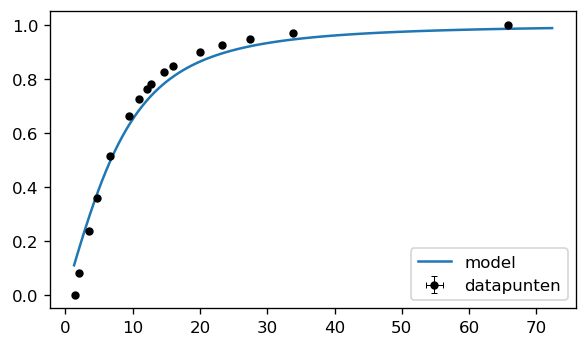

For parameter tau      :     Minimum at       0.08550351     ;     68% CI = [      0.08548448,       0.08552254]
----------------------------------------------------------------------------------------------------------------
Minimal χ² value       :     χ²_min      871719.05791251
Reduced χ² value       :     χ²_red       58114.60386083
P-value                :     p-value          0.00000000


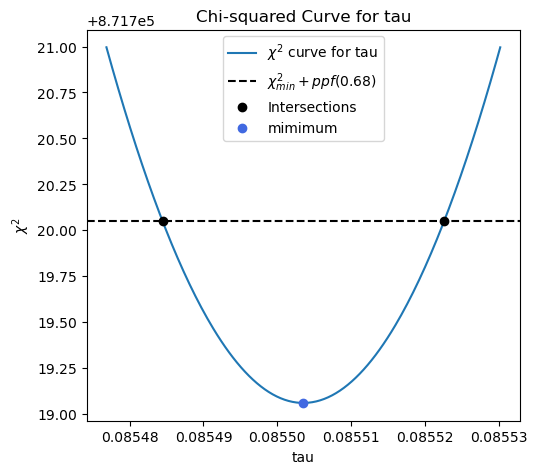

----------END---------------------------------------------------------------------------------------------------



In [14]:
#amplitude fitten
def model_amp(params, omega):
    tau = params
    return (omega*tau) / (np.sqrt(1 + (omega * tau)**2))
#normaliseren
amp_max = np.max(alle_amp)
amp_min = np.min(alle_amp)
amp_norm = (alle_amp - amp_min) / (amp_max - amp_min)

damp_norm = []
for i in range(len(alle_amp)):
    k = normaliseer_fout(alle_amp[i], amp_max, amp_min, damp[-1], damp[0], damp[i])
    damp_norm.append(k)

param_names = ['tau']
X_sq(((alle_hoekfreq, dhoek), (amp_norm, np.array(damp_norm).astype(float))), param_names, [0.1], model_amp)


0.649867388594361
0.707106781186548
0.00530976276847330
1.903000000000321e-05


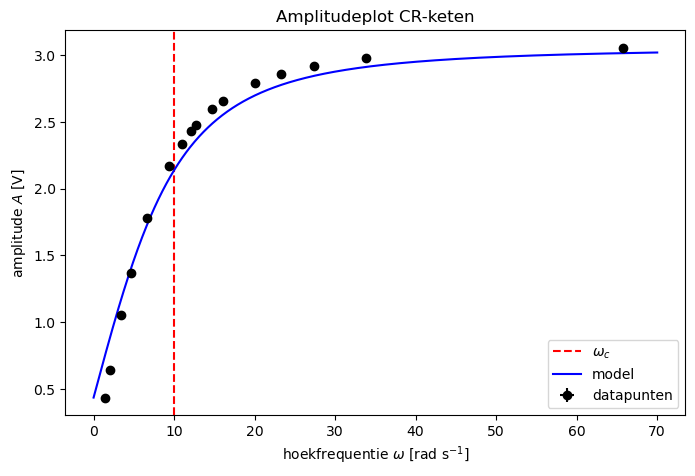

In [15]:
fig, ax = plt.subplots(figsize = (8, 5))
ax.errorbar(alle_hoekfreq, alle_amp, damp, dhoek, 'o', color = 'black', label = 'datapunten')
ax.axvline(1 / 0.1, color = 'red', linestyle = '--', label = r'$\omega_c$')
ax.set_xlabel(r'hoekfrequentie $\omega$ [rad s$^{-1}$]')
ax.set_ylabel(r'amplitude $A$ [V]')
ax.set_title(r'Amplitudeplot CR-keten')
OMEGA = np.linspace(0, 70, 1000)
tau = 0.08550351
model = ((OMEGA*tau) / (np.sqrt(1 + (OMEGA * tau)**2)))*(amp_max - amp_min) + amp_min
ax.plot(OMEGA, model, label = 'model', color = 'blue')
ax.legend()

def amplitude_c(tau, omega):
    o = sp.symbols('o')
    amp = o * tau / (sp.sqrt(1 + (o * tau)**2))
    return amp.subs(o, omega)

def fout_a(Tau, omega, dtau, domega):
    o, tau = sp.symbols('o tau')
    amp = o * tau / (sp.sqrt(1 + (o * tau)**2))
    s_func = sp.sqrt((sp.diff(amp, o))**2 * domega**2 + (sp.diff(amp, tau))**2 * dtau**2)
    s = s_func.subs([(tau, Tau), (o, omega)])
    return s

print(amplitude_c(tau, 10))
print(sp.N(sp.sqrt(1/2)))
print(fout_a(tau, 10, tau - 0.08548448, 0.141421356237309))
print(0.08550351 - 0.08548448)



---------START--------------------------------------------------------------------------------------------------


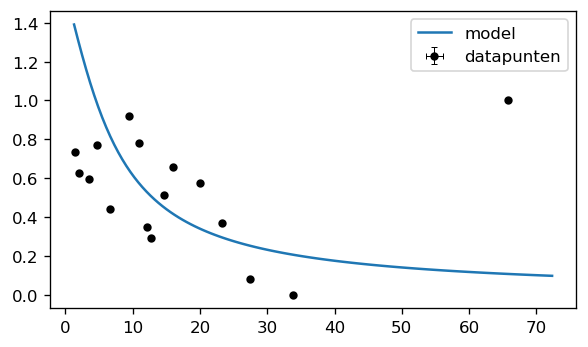

For parameter tau      :     Minimum at       0.14137007     ;     68% CI = [      0.14135114,       0.14138902]
----------------------------------------------------------------------------------------------------------------
Minimal χ² value       :     χ²_min     31872249.52458997
Reduced χ² value       :     χ²_red     2124816.63497266
P-value                :     p-value          0.00000000


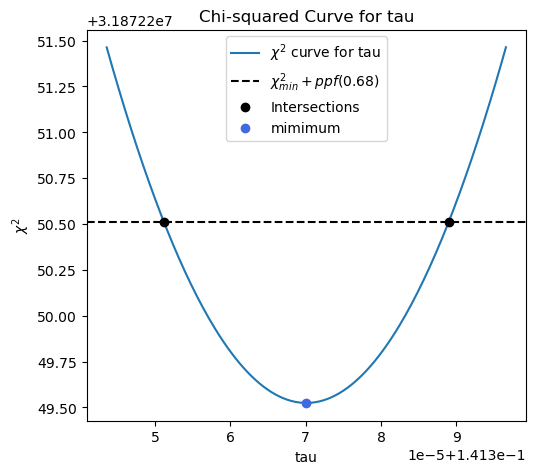

----------END---------------------------------------------------------------------------------------------------



In [16]:
#fitten en model faseplot
def model_fase(params, omega):
    tau = params
    return np.pi / 2 - np.arctan(omega * tau)
phi_max = np.max(alle_fase)
phi_min = np.min(alle_fase)
fase_norm = (alle_fase - phi_min) / (phi_max - phi_min)
#fout niet genormaliseerd want geen zin woeps
X_sq(((alle_hoekfreq, dhoek), (fase_norm, dfase)), param_names = ["tau"], initial_guess = [0.1], model = model_fase)

1.8930000000000335e-05


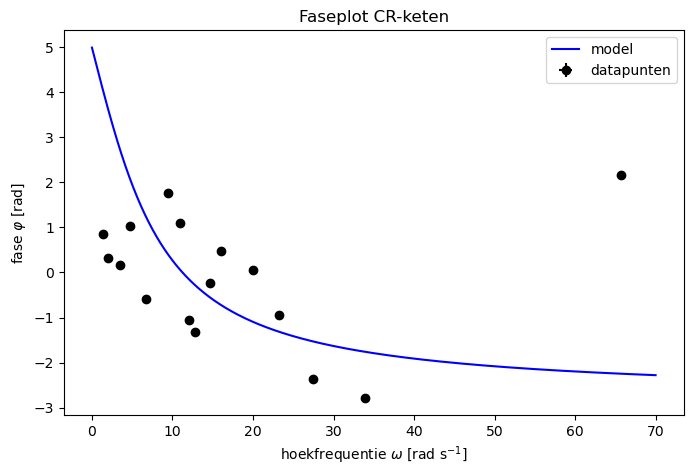

In [17]:
fig, ax = plt.subplots(figsize = (8, 5))
ax.errorbar(alle_hoekfreq, alle_fase, dfase, dhoek, 'o', color = 'black', label = 'datapunten')
ax.set_xlabel(r'hoekfrequentie $\omega$ [rad s$^{-1}$]')
ax.set_ylabel(r'fase $\varphi$ [rad]')
ax.set_title(r'Faseplot CR-keten')
model_phi = (np.pi / 2 - np.arctan(OMEGA * 0.14137007)) * (phi_max - phi_min) + phi_min
ax.plot(OMEGA, model_phi, color = 'blue', label = 'model')
ax.legend()
print(0.14137007 - 0.14135114)

In [18]:
def fout_oc(R, C, dr, dc):
    r, c = sp.symbols('r c')
    tau = 1 / (r*c)
    s_func = sp.sqrt(sp.diff(tau, r)**2 * dr**2 + sp.diff(tau, c)**2 * dc**2)
    s = s_func.subs([(r, R), (c, C)])
    return s
print(fout_oc(10e3, 10e-6, 0.01*10e3, 0.01*10e-6))
print(sp.N(sp.sqrt(2)*10**-1))

0.141421356237309
0.141421356237310


#PROEF 3

In [19]:
#test 1 - dempingscoëfficient
f = 0.6
R = np.array([100, 100e3, 100e3, 10e3, 100e3])
C = np.array([10e-6, 3.3e-9, 15e-9, 10e-6, 10e-6])
L = np.array([2.2e-3]*5)
dR = 0.01*R
dC = 0.01*C
dL = 0.01*L

def foutje_demping(R, L, C, dR, dC, dL):
    r, l, c = sp.symbols(' r l c')
    zeta = r / 2 * sp.sqrt(c / l)
    s_func = sp.sqrt((sp.diff(zeta, r))**2 * dR**2 + (sp.diff(zeta, c))**2 * dC**2 + (sp.diff(zeta, l))**2 * dL**2)
    s = s_func.subs([(r, R), (c, C), (l, L)])
    return s

demping = R / 2 * np.sqrt(C / L)
fout_demping = []
for i in range(len(R)):
    k = foutje_demping(R[i], L[i], C[i], dR[i], dC[i], dL[i])
    fout_demping.append(k)

print(demping)
demping.sort()
print(fout_demping)

[3.37099931e+00 6.12372436e+01 1.30558242e+02 3.37099931e+02
 3.37099931e+03]
[0.0412861411922385, 0.750000000000000, 1.59900537266708, 4.12861411922385, 41.2861411922385]


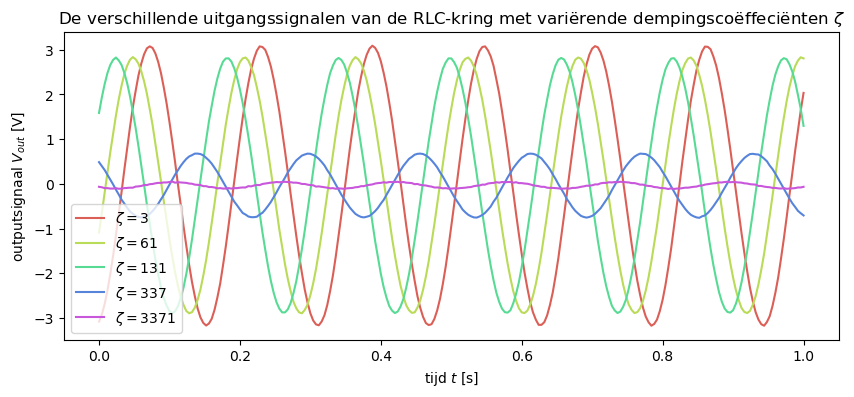

In [20]:
import seaborn as sns

#data plotten per dempingscoëfficient

getallen = [5, 1, 2, 4, 3]
alle_data = [] #wordt matrix: [0] is eerste meting enzovoort
for i in getallen:
    filename = f"data/Proef3 - kring{i}.txt"
    lijst = np.loadtxt(fname = filename, skiprows = 7, converters=lambda s: float(s.replace(b',', b'.'))).T[2]
    alle_data.append(lijst)

demping.sort()
demping_r = [3, 61, 131, 337, 3371]
fig, ax = plt.subplots(figsize = (10, 4))
colors = sns.color_palette("hls", 5)
for i in range(len(alle_data)):
    ax.plot(t[:251], alle_data[i][:251], color = colors[i], label = fr'$\zeta = {demping_r[i]}$')
ax.set_xlabel(r'tijd $t$ [s]')
ax.set_ylabel(r'outputsignaal $V_{out}$ [V]')
ax.set_title(r'De verschillende uitgangssignalen van de RLC-kring met variërende dempingscoëffeciënten $\zeta$')
ax.legend()

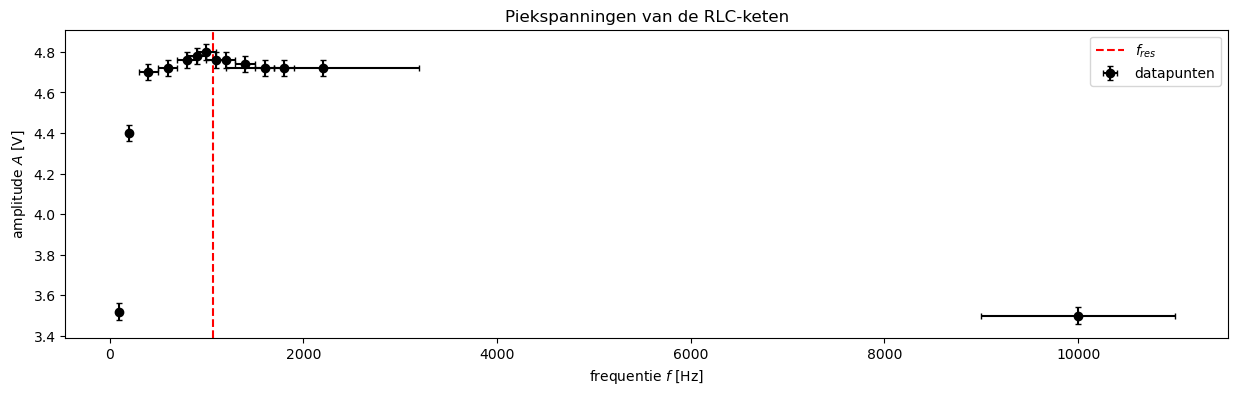

In [21]:
#tweede proef - resonantie (0.04 = reolutie)
R = 100
L = 2.2e-3
C = 10e-6
fig, ax = plt.subplots(figsize = (15, 4))
f = np.array([100, 200, 400, 600, 800, 900, 1000, 1100, 1200, 1400, 1600, 1800, 2200, 10000])
piek = np.array([3.52, 4.40, 4.70, 4.72, 4.76, 4.78, 4.80, 4.76, 4.76, 4.74, 4.72, 4.72, 4.72, 3.50])
dpiek = np.array([0.04]*len(f))
df = [0.1*100, 0.1*100, 0.1*1000, 0.1*1000, 0.1*1000, 0.1*1000, 0.1*1000, 0.1*1000, 0.1*1000, 0.1*1000, 0.1*1000, 0.1*1000, 0.1*10000, 0.1*10000]

ax.errorbar(f, piek, dpiek, df, color = 'black', label = 'datapunten', fmt = 'o', capsize = 2.5)
ax.axvline(x = (1 / (np.sqrt(L*C))) * (1 / (2 * np.pi)), color = 'red', linestyle = '--', label = r'$f_{res}$')
ax.set_xlabel(r'frequentie $f$ [Hz]')
ax.set_ylabel(r'amplitude $A$ [V]')
ax.set_title(r'Piekspanningen van de RLC-keten')
ax.legend()

In [22]:
L = 2.2e-3
C = 10e-6
dL = 0.01*L
dC = 0.01*C

fres = 1 / (2 * np.pi) * 1 / (np.sqrt(L*C))

def fout_fres(L, C, dL, dC):
    l, c = sp.symbols('l c')
    f = 1 / (2 * sp.pi) * 1 / (sp.sqrt(l * c))
    s_func = sp.sqrt((sp.diff(f, l))**2 * dL**2 + (sp.diff(f, c))**2 * dC**2)
    s = s_func.subs([(l, L), (c, C)])
    return s

print(fres, sp.N(fout_fres(L, C, dL, dC)))

1073.0224074290095 7.58741420658167
